In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
data = {
    "AnnualIncome":[15,18,20,22,25
                    ,70,75,78,80,85],
    "SpendingScore":[89,85,78,90,82,
                     20,25,15,22,18]
}
df = pd.DataFrame(data)
df.head()

,AnnualIncome,SpendingScore
0,15,89
1,18,85
2,20,78
3,22,90
4,25,82


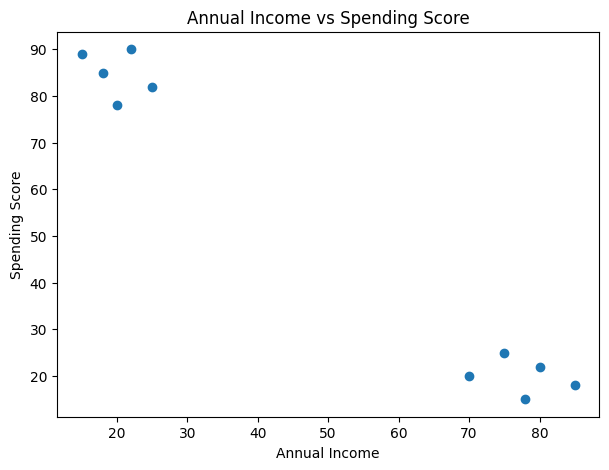

In [3]:
plt.figure(figsize=(7,5))
plt.scatter(df["AnnualIncome"],df["SpendingScore"])
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Annual Income vs Spending Score")
plt.show()

In [4]:
x = df[["AnnualIncome","SpendingScore"]]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
print(x_scaled.round(2))

[[-1.16  1.12]
 [-1.06  1.  ]
 [-0.99  0.78]
 [-0.92  1.15]
 [-0.82  0.91]
 [ 0.73 -0.99]
 [ 0.9  -0.84]
 [ 1.   -1.15]
 [ 1.07 -0.93]
 [ 1.24 -1.05]]


In [5]:
kmeans = KMeans(n_clusters=2,random_state=42,n_init=10)
kmeans.fit(x_scaled)
df["Cluster"] = kmeans.labels_
print(df)

   AnnualIncome  SpendingScore  Cluster
0            15             89        0
1            18             85        0
2            20             78        0
3            22             90        0
4            25             82        0
5            70             20        1
6            75             25        1
7            78             15        1
8            80             22        1
9            85             18        1


In [6]:
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
print("Cluster centroids in original unit:")
print(centroids_original.round(2))

Cluster centroids in original unit:
[[20.  84.8]
 [77.6 20. ]]


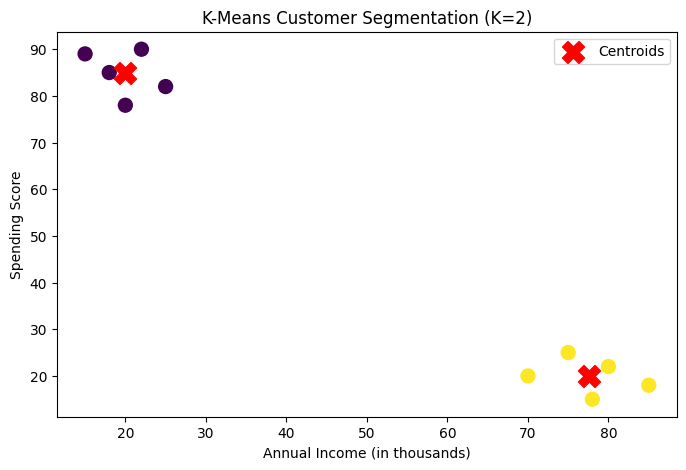

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation (K=2)")
plt.legend()
plt.show()